# Two Independent Sample T test


# Problem Statement :

Does smoking status significantly impact individual medical insurance costs? Use statistical hypothesis testing to determine if the average insurance charges for smokers are different from the average charges for non-smokers.

H₀:There is no significant difference in the mean insurance charges between smokers and non-smokers.

μ₁ = μ₂




H₁:There is a significant difference in the mean insurance charges between smokers and non-smokers.

μ₁ ≠ μ₂


# Using SCIPY

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm, t , ttest_ind


In [3]:
df=pd.read_csv("insurance.csv")


In [4]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


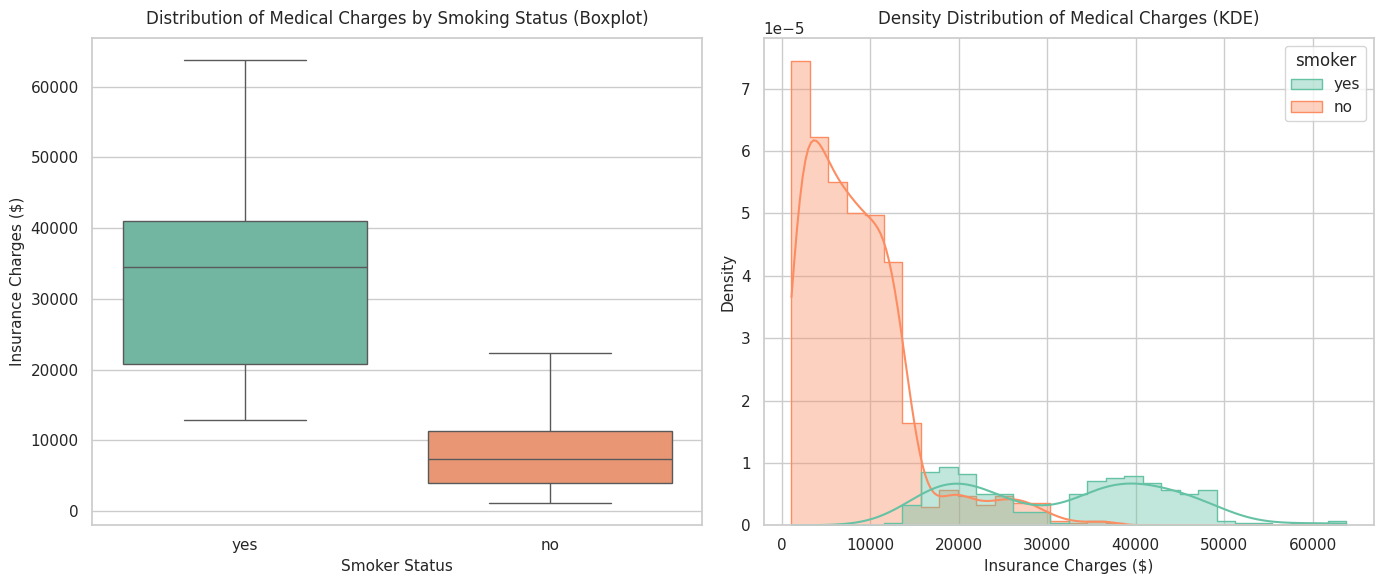

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean aesthetic style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Box Plot (To visualize summary statistics and outliers)
sns.boxplot(
    data=df,
    x='smoker',
    y='charges',
    ax=axes[0],
    palette='Set2',
    hue='smoker',
    legend=False,
    showfliers=False
)
axes[0].set_title('Distribution of Medical Charges by Smoking Status (Boxplot)', fontsize=12, pad=10)
axes[0].set_xlabel('Smoker Status', fontsize=11)
axes[0].set_ylabel('Insurance Charges ($)', fontsize=11)

# 2. KDE Plot (To visualize the overlapping density curves)
sns.histplot(
    data=df,
    x='charges',
    hue='smoker',
    kde=True,
    ax=axes[1],
    palette='Set2',
    element='step',
    stat='density',
    alpha=0.4
)
axes[1].set_title('Density Distribution of Medical Charges (KDE)', fontsize=12, pad=10)
axes[1].set_xlabel('Insurance Charges ($)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)

# Adjust layouts and display
plt.tight_layout()
plt.show()


In [6]:
smokers=df[df['smoker']=="yes"]['charges']
non_smokers=df[df['smoker']=='no']['charges']

In [7]:
Smokers_mean=np.mean(smokers)
non_smokers_mean=np.mean(non_smokers)

In [8]:
TS,p_val=ttest_ind(smokers,non_smokers,equal_var=False)


In [9]:
TS

np.float64(32.751887766341824)

In [10]:
p_val

np.float64(5.88946444671698e-103)

#Using Stats Model


In [12]:
from statsmodels.stats.api import ttest_ind

t_stats,p_value,ddof=ttest_ind(smokers,non_smokers,alternative='two-sided')

In [13]:
t_stats

np.float64(46.66492117272373)

In [14]:
p_value

np.float64(8.271435842175338e-283)

In [15]:
if( p_val<0.05):
  print("We Reject the Null Hypothesis")
else:
  print("Fail To Reject the NUll Hypothesis")

We Reject the Null Hypothesis


# Conclusion:

 There is overwhelmingly strong statistical evidence that the true mean medical insurance charges for smokers are significantly different from the true mean charges for non-smokers.
